In [1]:
%pip install -q qiskit qiskit-aer matplotlib pandas pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 41.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 63.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 54.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.4 MB/s eta 0:00:00


In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error
from qiskit.visualization import plot_histogram

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

MESSAGES = ["00", "01", "10", "11"]
SHOTS = 4096

def superdense_circuit(message, bit_flip=False, noisy_pair=False):
    if message not in MESSAGES:
        raise ValueError("Message must be 00, 01, 10, or 11.")

    qc = QuantumCircuit(2, 2)

    # 1. Prepare the shared Bell pair.
    qc.h(0)
    qc.cx(0, 1)
    qc.barrier()

    # Noise location for Exercise 5: before Alice encodes.
    if noisy_pair:
        qc.id(0)
        qc.barrier()

    # 2. Alice encodes two classical bits on her qubit.
    # 00 -> I; 01 -> X; 10 -> Z; 11 -> X then Z.
    if message[1] == "1":
        qc.x(0)
    if message[0] == "1":
        qc.z(0)

    qc.barrier()

    # 3. Alice transmits qubit 0 to Bob.
    # Optional deterministic transmission error.
    if bit_flip:
        qc.x(0)

    qc.barrier()

    # 4. Bob decodes using both qubits.
    qc.cx(0, 1)
    qc.h(0)

    # Qiskit prints classical bits as c1 c0.
    qc.measure(0, 1)
    qc.measure(1, 0)

    return qc

def run_circuit(qc, shots=SHOTS, noise_model=None):
    simulator = AerSimulator(noise_model=noise_model)

    # Run directly to retain the identity noise location.
    result = simulator.run(
        qc,
        shots=shots,
        seed_simulator=42
    ).result()

    return result.get_counts()

def accuracy(counts, message):
    return counts.get(message, 0) / sum(counts.values())

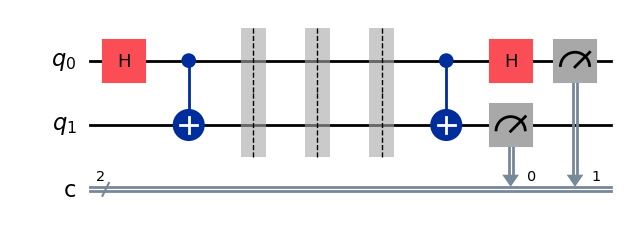

Sent message: 00
Measurement counts: {'00': 4096}
Decoding accuracy: 100.00%


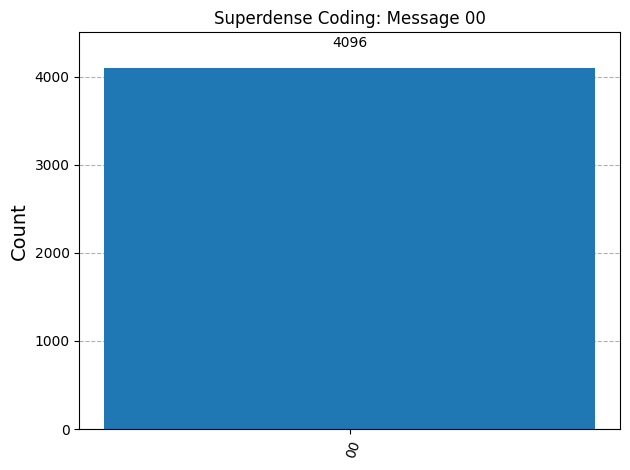

In [3]:
qc_00 = superdense_circuit("00")

display(qc_00.draw(output="mpl"))

counts_00 = run_circuit(qc_00)

print("Sent message: 00")
print("Measurement counts:", counts_00)
print(f"Decoding accuracy: {accuracy(counts_00, '00'):.2%}")

assert counts_00 == {"00": SHOTS}

display(plot_histogram(counts_00, title="Superdense Coding: Message 00"))
plt.show()

In [4]:
ideal_rows = []

for message in MESSAGES:
    counts = run_circuit(superdense_circuit(message))
    decoded = max(counts, key=counts.get)

    ideal_rows.append({
        "Sent message": message,
        "Decoded message": decoded,
        "Counts": counts,
        "Accuracy (%)": 100 * accuracy(counts, message)
    })

    assert counts == {message: SHOTS}

ideal_results = pd.DataFrame(ideal_rows)
display(ideal_results)

,Sent message,Decoded message,Counts,Accuracy (%)
0,00,00,{'00': 4096},100.0
1,01,01,{'01': 4096},100.0
2,10,10,{'10': 4096},100.0
3,11,11,{'11': 4096},100.0


In [5]:
bit_flip_rows = []

for message in MESSAGES:
    qc = superdense_circuit(message, bit_flip=True)
    counts = run_circuit(qc)
    decoded = max(counts, key=counts.get)

    expected_wrong_message = message[0] + str(1 - int(message[1]))
    assert counts == {expected_wrong_message: SHOTS}

    bit_flip_rows.append({
        "Sent message": message,
        "Decoded message": decoded,
        "Counts": counts,
        "Accuracy (%)": 100 * accuracy(counts, message)
    })

bit_flip_results = pd.DataFrame(bit_flip_rows)
display(bit_flip_results)

print("A transmission X error flips the second decoded bit.")
print("Because every transmission has an error here, accuracy is 0%.")

,Sent message,Decoded message,Counts,Accuracy (%)
0,00,01,{'01': 4096},0.0
1,01,00,{'00': 4096},0.0
2,10,11,{'11': 4096},0.0
3,11,10,{'10': 4096},0.0


A transmission X error flips the second decoded bit.
Because every transmission has an error here, accuracy is 0%.


In [6]:
number_of_messages = 100
bits_per_message = 2

classical_bits = number_of_messages * bits_per_message
transmitted_qubits = number_of_messages
required_bell_pairs = number_of_messages

comparison = pd.DataFrame([
    {
        "Method": "Classical communication",
        "Message payload": f"{classical_bits} classical bits",
        "Pre-shared resource": "None"
    },
    {
        "Method": "Superdense coding",
        "Message payload": f"{transmitted_qubits} transmitted qubits",
        "Pre-shared resource": f"{required_bell_pairs} Bell pairs"
    }
])

display(comparison)

print(
    f"For {number_of_messages} two-bit messages, classical communication "
    f"sends {classical_bits} bits. Superdense coding sends "
    f"{transmitted_qubits} qubits using {required_bell_pairs} pre-shared "
    "Bell pairs. Each pair is consumed during decoding. If distributing "
    "each pair requires sending one additional qubit, the total is "
    f"{2 * number_of_messages} qubit transmissions, including preparation."
)

,Method,Message payload,Pre-shared resource
0,Classical communication,200 classical bits,None
1,Superdense coding,100 transmitted qubits,100 Bell pairs


For 100 two-bit messages, classical communication sends 200 bits. Superdense coding sends 100 qubits using 100 pre-shared Bell pairs. Each pair is consumed during decoding. If distributing each pair requires sending one additional qubit, the total is 200 qubit transmissions, including preparation.


,Sent message,Most frequent decoding,Accuracy (%),Observed error (%),Expected error (%)
0,00,00,90.15,9.85,10.0
1,01,01,90.31,9.69,10.0
2,10,10,90.47,9.53,10.0
3,11,11,89.99,10.01,10.0


Shared-pair fidelity: 0.90
Expected decoding error: 10.00%
Average simulated error: 9.77%


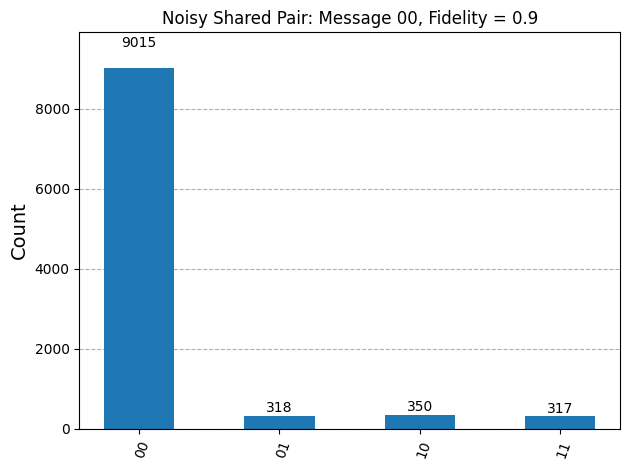

In [7]:
F = 0.90
NOISY_SHOTS = 10000

if not 0 <= F <= 1:
    raise ValueError("Fidelity must be between 0 and 1.")

# Applying I, X, Y, or Z to one half of a Bell pair
# produces the four possible Bell states.
pair_error = pauli_error([
    ("I", F),
    ("X", (1 - F) / 3),
    ("Y", (1 - F) / 3),
    ("Z", (1 - F) / 3)
])

noise_model = NoiseModel()
noise_model.add_quantum_error(pair_error, ["id"], [0])

noisy_rows = []
noisy_counts = {}

for message in MESSAGES:
    qc = superdense_circuit(message, noisy_pair=True)

    counts = run_circuit(
        qc,
        shots=NOISY_SHOTS,
        noise_model=noise_model
    )

    noisy_counts[message] = counts
    observed_accuracy = accuracy(counts, message)

    noisy_rows.append({
        "Sent message": message,
        "Most frequent decoding": max(counts, key=counts.get),
        "Accuracy (%)": 100 * observed_accuracy,
        "Observed error (%)": 100 * (1 - observed_accuracy),
        "Expected error (%)": 100 * (1 - F)
    })

noisy_results = pd.DataFrame(noisy_rows)
display(noisy_results)

print(f"Shared-pair fidelity: {F:.2f}")
print(f"Expected decoding error: {1 - F:.2%}")
print(
    "Average simulated error: "
    f"{noisy_results['Observed error (%)'].mean():.2f}%"
)

display(
    plot_histogram(
        noisy_counts["00"],
        title=f"Noisy Shared Pair: Message 00, Fidelity = {F}"
    )
)
plt.show()